# Hospitalisations hebdomadaires (COVID-19, grippe, RSV) — Nettoyage du dataset

**Objectif :** passer du fichier brut (une ligne par combinaison réseau × date × âge × sexe × état × …)
à **une série temporelle propre** : une ligne par semaine, une colonne par virus.

Plan :
1. Charger et comprendre les colonnes
2. Filtrer les lignes (garder uniquement le niveau national, taux hebdomadaire)
3. Garder uniquement les colonnes utiles
4. Mettre au format « large » (une colonne par réseau)
5. Traiter les semaines manquantes
6. Visualiser et sauvegarder

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("dataset.csv")
print("Dimensions :", data.shape)
print(data.dtypes)

Dimensions : (124904, 12)
Surveillance Network        str
Season                      str
Date Type                   str
Date                        str
Age Category                str
Race                        str
Sex                         str
State                       str
Data Type                   str
Estimate Type               str
Rate Type                   str
Estimate                float64
dtype: object


## 1. Comprendre les colonnes

Pour chaque colonne catégorielle, on regarde les valeurs possibles.
Le but : comprendre **pourquoi il y a plusieurs lignes pour une même date**.

In [2]:
colonnes_cat = ["Surveillance Network", "Date Type", "Data Type", "Estimate Type",
                "Rate Type", "Age Category", "Sex", "Race", "State"]

for col in colonnes_cat:
    print(f"\n--- {col} ({data[col].nunique()} valeurs) ---")
    print(data[col].value_counts(dropna=False).head(8).to_string())


--- Surveillance Network (4 valeurs) ---
Surveillance Network
Combined       35542
RSV-NET        33096
COVID-NET      31018
FluSurv-NET    25248

--- Date Type (2 valeurs) ---
Date Type
Week Ending Date    123128
Season                1776

--- Data Type (6 valeurs) ---
Data Type
Cumulative Rate                    61564
Weekly Rate                        61564
Admitted to Intensive Care Unit      509
Invasive Mechanical Ventilation      509
In-Hospital Death                    391
≥1 Underlying Condition              367

--- Estimate Type (2 valeurs) ---
Estimate Type
Rate per 100,000    123128
Percent               1776

--- Rate Type (3 valeurs) ---
Rate Type
Observed        108934
Age-Adjusted     14170
NaN               1776
Estimated           24

--- Age Category (33 valeurs) ---
Age Category
Overall     73392
18-49 yr     2772
12-17 yr     2772
18-29 yr     2772
0-<1 yr      2772
1-4 yr       2772
75+ yr       2772
Adults       2772

--- Sex (3 valeurs) ---
Sex
All       1193

**Lecture :** pour une même semaine, le fichier contient le taux **cumulé** *et* **hebdomadaire**,
découpé par âge, sexe, origine et état. Une série temporelle = **une seule valeur par date**,
donc on doit fixer chacune de ces dimensions.

| Colonne | Valeur gardée | Raison |
|---|---|---|
| `Date Type` | `Week Ending Date` | `Season` = résumés par saison (pas une série) |
| `Data Type` | `Weekly Rate` | Le taux cumulé remonte toute la saison puis repart à 0 |
| `Age Category` | `Overall` | Toute la population |
| `Sex`, `Race` | `All` | Idem |
| `State` | `Overall` | Niveau national |
| `Rate Type` | `Observed` | `Estimated` = 12 lignes (corrections des 3 dernières semaines) |

## 2. Filtrer les lignes

In [3]:
filtres = {
    "Date Type":    "Week Ending Date",
    "Data Type":    "Weekly Rate",
    "Age Category": "Overall",
    "Sex":          "All",
    "Race":         "All",
    "State":        "Overall",
    "Rate Type":    "Observed",
}

df = data.copy()
print(f"{'Départ':<15} {len(df):>7} lignes")
for col, val in filtres.items():
    df = df[df[col] == val]
    print(f"{col:<15} {len(df):>7} lignes")

Départ           124904 lignes
Date Type        123128 lignes
Data Type         61564 lignes
Age Category      36616 lignes
Sex               33844 lignes
Race              19829 lignes
State              1429 lignes
Rate Type          1417 lignes


Vérification : il doit rester **exactement une valeur par (réseau, date)**.

In [4]:
doublons = df.duplicated(subset=["Surveillance Network", "Date"]).sum()
print("Doublons (réseau, date) :", doublons)
print("Valeurs manquantes dans Estimate :", df["Estimate"].isna().sum())
print(df.groupby("Surveillance Network").size())

Doublons (réseau, date) : 0
Valeurs manquantes dans Estimate : 0
Surveillance Network
COVID-NET      345
Combined       398
FluSurv-NET    297
RSV-NET        377
dtype: int64


## 3. Garder uniquement les colonnes utiles

Toutes les autres colonnes sont maintenant **constantes** → elles n'apportent plus d'information.
On garde : `Date`, `Surveillance Network`, `Estimate` (taux pour 100 000 habitants).

In [5]:
df = df[["Date", "Surveillance Network", "Estimate"]].copy()
df["Date"] = pd.to_datetime(df["Date"])

# Noms plus courts
df["Surveillance Network"] = df["Surveillance Network"].map({
    "COVID-NET": "covid",
    "FluSurv-NET": "grippe",
    "RSV-NET": "rsv",
    "Combined": "combined",
})
print(df.head())

            Date Surveillance Network  Estimate
61864 2020-03-07                covid       0.1
61865 2020-03-14                covid       0.6
61866 2020-03-21                covid       2.9
61867 2020-03-28                covid       7.6
61868 2020-04-04                covid       9.5


## 4. Format large : une ligne par semaine, une colonne par virus

`asfreq("7D")` crée toutes les semaines du calendrier : les semaines absentes deviennent visibles (NaN).

In [6]:
series = (
    df.pivot(index="Date", columns="Surveillance Network", values="Estimate")
      .sort_index()
      .asfreq("7D")
)
series = series[["covid", "grippe", "rsv", "combined"]]
series.columns.name = None

print("Période :", series.index.min().date(), "→", series.index.max().date())
print("Nombre de semaines :", len(series))
print(series.tail())

Période : 2018-10-06 → 2026-10-10
Nombre de semaines : 419
            covid  grippe  rsv  combined
Date                                    
2026-09-12    1.0     0.4  0.1       1.5
2026-09-19    1.2     0.5  0.0       1.7
2026-09-26    1.2     0.8  0.0       2.0
2026-10-03    1.1     0.9  0.1       2.0
2026-10-10    0.8     0.7  0.1       1.6


## 5. Semaines manquantes : où sont-elles ?

In [7]:
print("NaN par colonne :")
print(series.isna().sum())

for col in series.columns:
    manquantes = series.index[series[col].isna()]
    debut = series[col].first_valid_index()
    apres_debut = manquantes[manquantes >= debut]
    mois = apres_debut.month.value_counts().sort_index()
    print(f"\n{col}: début {debut.date()}, {len(apres_debut)} semaines manquantes après le début")
    if len(mois):
        print("  par mois :", mois.to_dict())

NaN par colonne :
covid        74
grippe      122
rsv          42
combined     21
dtype: int64

covid: début 2020-03-07, 0 semaines manquantes après le début

grippe: début 2018-10-06, 122 semaines manquantes après le début
  par mois : {5: 18, 6: 23, 7: 27, 8: 27, 9: 25, 10: 2}

rsv: début 2018-10-06, 42 semaines manquantes après le début
  par mois : {5: 7, 6: 9, 7: 8, 8: 10, 9: 8}

combined: début 2018-10-06, 21 semaines manquantes après le début
  par mois : {5: 3, 6: 5, 7: 4, 8: 5, 9: 4}


**Interprétation :**
- **covid** : les NaN sont *avant* mars 2020 → le virus n'existait pas. **Aucun trou ensuite.**
- **combined** : un seul trou, en **été 2019** (mai → septembre). **Aucun trou ensuite.**
- **grippe / rsv** : trous chaque été (les réseaux ne collectent pas hors saison).

⚠️ Une semaine manquante = « pas mesuré », **pas** « 0 cas ». Plutôt que d'inventer des valeurs,
on **évite le problème** : on garde uniquement les séries sans trous, sur une période où elles sont complètes.

**Décision :**
- on garde **covid** et **combined** ;
- on écarte **grippe** et **rsv** (trous récurrents) ;
- période commune : **7 mars 2020 → fin de la série** (début de covid ; combined y est déjà complet).

In [8]:
debut = series["covid"].first_valid_index()
clean = series.loc[debut:, ["covid", "combined"]].copy()

print("Période :", clean.index.min().date(), "→", clean.index.max().date())
print("Nombre de semaines :", len(clean))
print("Valeurs manquantes :", clean.isna().sum().to_dict())
print("Écarts entre dates :", clean.index.to_series().diff().dropna().unique())

Période : 2020-03-07 → 2026-10-10
Nombre de semaines : 345
Valeurs manquantes : {'covid': 0, 'combined': 0}
Écarts entre dates : <TimedeltaArray>
['7 days']
Length: 1, dtype: timedelta64[us]


**Ce qu'on perd :** la saison 2019-20 de combined (oct. 2019 → mars 2020) et les séries grippe/RSV.
**Ce qu'on gagne :** 345 semaines consécutives, **sans aucune valeur inventée**, identiques pour tous les modèles.

## 6. Visualisation

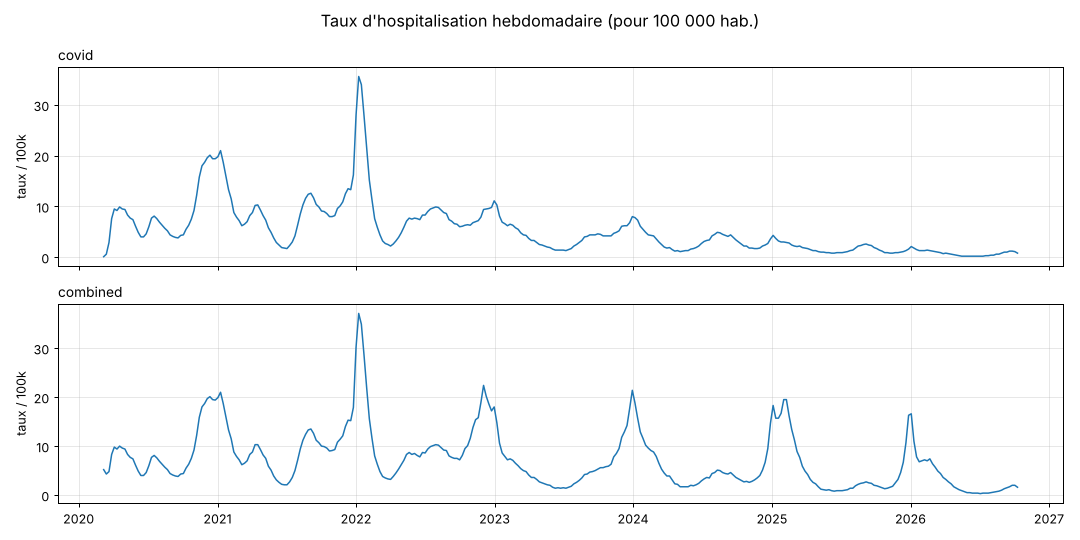

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, col in zip(axes, ["covid", "combined"]):
    ax.plot(clean.index, clean[col], lw=1.2)
    ax.set_title(col, loc="left", fontsize=11)
    ax.set_ylabel("taux / 100k")
    ax.grid(alpha=0.3)
fig.suptitle("Taux d'hospitalisation hebdomadaire (pour 100 000 hab.)", fontsize=13)
plt.tight_layout()
plt.show()

Moyenne par mois → confirme une **saisonnalité annuelle** (période s = 52 semaines), pic en décembre–janvier.

In [10]:
print(clean.groupby(clean.index.month).mean().round(2))

      covid  combined
Date                 
1     11.73     16.97
2      5.60      9.98
3      3.26      5.75
4      4.11      5.05
5      3.65      4.01
6      2.68      2.86
7      3.89      4.11
8      4.89      5.12
9      4.81      5.23
10     4.86      5.92
11     6.33      8.88
12     8.95     14.99


## 7. Sauvegarde

In [11]:
clean.index.name = "date"
clean.to_csv("hospitalisations_hebdo_clean.csv")
print(clean.shape)
print(clean.describe().round(2))

(345, 2)
        covid  combined
count  345.00    345.00
mean     5.28      7.15
std      5.13      5.88
min      0.10      0.30
25%      1.70      2.70
50%      4.10      5.70
75%      7.50      9.50
max     35.60     37.10


## Résumé

- Fichier brut : **124 904 lignes × 12 colonnes**
- Fichier propre : **345 semaines consécutives** (7 mars 2020 → 10 octobre 2026), colonnes `covid` et `combined`, **0 valeur manquante**
- grippe et RSV écartés : trous chaque été (« non mesuré » ≠ 0 cas), on préfère ne rien inventer
- Observations à garder en tête pour la modélisation :
  - forte saisonnalité annuelle (s = 52) ;
  - début très chaotique (vagues COVID 2020–2022), puis série plus calme et plus saisonnière ;
  - variance plus grande lors des pics → une transformation `log1p` sera probablement utile.